# Pulsar Candidate Classification & Clustering (HTRU2)
UE24CS352A – Machine Learning mini-project  
**O P Medha** (PES2UG24CS332) · **P Dhanush** (PES2UG24CS333)

This notebook contains the whole project in one file: data utilities, GDA / Random Forest / SOM implemented from scratch,
the supervised and unsupervised experiments, and the final run.  
Run all cells from top to bottom (**Run All**). Place `HTRU_2.csv` in a `data/` folder next to this notebook.

## 1. Imports

In [1]:
import json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, recall_score, precision_score, f1_score, roc_curve,
                             precision_recall_curve, roc_auc_score, silhouette_score)

## 2. Data loading, splitting and oversampling

In [12]:
FEATURES = ["ip_mean", "ip_std", "ip_kurtosis", "ip_skew",
            "dmsnr_mean", "dmsnr_std", "dmsnr_kurtosis", "dmsnr_skew"]


def load_htru2(path="data/HTRU_2.csv"):
    """UCI HTRU_2.csv has no header: 8 features then the class label (last column)."""
    df = pd.read_csv(path, header=None, names=FEATURES + ["label"])
    return df[FEATURES].values.astype(float), df["label"].values.astype(int)


def make_synthetic(n=6000, pulsar_frac=0.09, seed=0):
    """Fake data with the same shape as HTRU2. ONLY for smoke-testing the code."""
    rng = np.random.default_rng(seed)
    y = (rng.random(n) < pulsar_frac).astype(int)
    X = rng.normal(size=(n, 8)) * [25, 6, 1.5, 6, 30, 15, 4, 40] + [110, 47, 0.5, 1, 12, 26, 8, 100]
    X[y == 1] += [-60, -8, 3, 25, 50, 20, -4, 80]
    return X, y


def split(X, y, test_size=0.2, seed=42):
    return train_test_split(X, y, test_size=test_size, stratify=y, random_state=seed)


def oversample(X, y, seed=0):
    """Random minority oversampling -> ~50/50 classes. Apply to TRAINING data only."""
    rng = np.random.default_rng(seed)
    pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]
    extra = rng.choice(pos, size=len(neg) - len(pos), replace=True)
    idx = rng.permutation(np.concatenate([neg, pos, extra]))
    return X[idx], y[idx]

## 3. Gaussian Discriminant Analysis (from scratch) – baseline

In [ ]:
"""Gaussian Discriminant Analysis (shared covariance) implemented from scratch."""


class GDA:
    def fit(self, X, y):
        self.phi = y.mean()
        self.mu0, self.mu1 = X[y == 0].mean(0), X[y == 1].mean(0)
        mu = np.where(y[:, None] == 1, self.mu1, self.mu0)
        D = X - mu
        self.sigma_inv = np.linalg.pinv(D.T @ D / len(X))
        return self

    def predict_proba(self, X):
        w = self.sigma_inv @ (self.mu1 - self.mu0)
        b = (-0.5 * (self.mu1 @ self.sigma_inv @ self.mu1 - self.mu0 @ self.sigma_inv @ self.mu0)
             + np.log(self.phi / (1 - self.phi)))
        z = np.clip(X @ w + b, -50, 50)
        return 1 / (1 + np.exp(-z))

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

## 4. Random Forest (from scratch)

In [14]:
"""Random Forest implemented from scratch (entropy / information gain)."""


def _entropy(y):
    if len(y) == 0:
        return 0.0
    p = np.bincount(y, minlength=2) / len(y)
    p = p[p > 0]
    return -(p * np.log2(p)).sum()


class _Node:
    __slots__ = ("feat", "thr", "left", "right", "p")


class DecisionTree:
    def __init__(self, max_depth=12, min_samples_split=5, max_features=3, n_thresholds=16, rng=None):
        self.max_depth, self.min_split = max_depth, min_samples_split
        self.max_features, self.n_thr = max_features, n_thresholds
        self.rng = rng or np.random.default_rng()

    def fit(self, X, y):
        self.root = self._build(X, y, 0)
        return self

    def _best_split(self, X, y):
        parent, n = _entropy(y), len(y)
        best = (0.0, None, None)
        for f in self.rng.choice(X.shape[1], self.max_features, replace=False):
            thrs = np.unique(np.percentile(X[:, f], np.linspace(5, 95, self.n_thr)))
            for t in thrs:
                m = X[:, f] <= t
                nl = m.sum()
                if nl == 0 or nl == n:
                    continue
                gain = parent - nl / n * _entropy(y[m]) - (n - nl) / n * _entropy(y[~m])
                if gain > best[0]:
                    best = (gain, f, t)
        return best

    def _build(self, X, y, depth):
        node = _Node()
        node.p = y.mean()
        node.feat = node.left = node.right = None
        if depth >= self.max_depth or len(y) < self.min_split or node.p in (0.0, 1.0):
            return node
        gain, f, t = self._best_split(X, y)
        if f is None:
            return node
        m = X[:, f] <= t
        node.feat, node.thr = f, t
        node.left, node.right = self._build(X[m], y[m], depth + 1), self._build(X[~m], y[~m], depth + 1)
        return node

    def predict_proba(self, X):
        out = np.empty(len(X))
        for i, x in enumerate(X):
            n = self.root
            while n.feat is not None:
                n = n.left if x[n.feat] <= n.thr else n.right
            out[i] = n.p
        return out


class RandomForestScratch:
    def __init__(self, n_estimators=50, max_depth=12, min_samples_split=5, max_features=3, seed=0):
        self.n, self.seed = n_estimators, seed
        self.kw = dict(max_depth=max_depth, min_samples_split=min_samples_split, max_features=max_features)

    def fit(self, X, y):
        rng = np.random.default_rng(self.seed)
        self.trees = []
        for _ in range(self.n):
            idx = rng.integers(0, len(X), len(X))  # bootstrap sample
            self.trees.append(DecisionTree(rng=rng, **self.kw).fit(X[idx], y[idx]))
        return self

    def predict_proba(self, X):
        return np.mean([t.predict_proba(X) for t in self.trees], axis=0)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

## 5. Self-Organizing Map (from scratch)

In [ ]:
"""Self-Organizing Map implemented from scratch with NumPy."""


class SOM:
    def __init__(self, rows=5, cols=5, epochs=100, lr0=0.5, seed=0):
        self.rows, self.cols, self.epochs, self.lr0, self.seed = rows, cols, epochs, lr0, seed

    def fit(self, X):
        rng = np.random.default_rng(self.seed)
        self.W = X[rng.choice(len(X), self.rows * self.cols)].copy()  
        self.grid = np.array([(r, c) for r in range(self.rows) for c in range(self.cols)], float)
        sigma0 = max(self.rows, self.cols) / 2
        for e in range(self.epochs):
            decay = np.exp(-e / self.epochs)
            lr, sigma = self.lr0 * decay, sigma0 * decay
            for x in X[rng.permutation(len(X))]:
                bmu = np.argmin(((self.W - x) ** 2).sum(1))          
                d2 = ((self.grid - self.grid[bmu]) ** 2).sum(1)      
                theta = np.exp(-d2 / (2 * sigma ** 2))                
                self.W += lr * theta[:, None] * (x - self.W)
        return self

    def predict(self, X):
        d = ((X[:, None, :] - self.W[None]) ** 2).sum(2)
        return d.argmin(1)

## 6. Supervised experiments (GDA vs Random Forest)
Oversampling is applied to training data only; the decision threshold is chosen on a validation split of the training data.

In [ ]:
def proba(m, X):
    """Probability of the pulsar class for sklearn or scratch models."""
    return m.predict_proba(X)[:, 1] if hasattr(m, "classes_") else m.predict_proba(X)


def metrics(y, p, thr=0.5):
    pred = (p >= thr).astype(int)
    return dict(accuracy=accuracy_score(y, pred), recall=recall_score(y, pred),
                precision=precision_score(y, pred, zero_division=0), f1=f1_score(y, pred),
                auc=roc_auc_score(y, p))


def cv_scores(make_model, X, y, thr=0.5, k=5):
    """K-fold CV; oversampling happens inside each fold on training data only."""
    rows = []
    for tr, va in StratifiedKFold(k, shuffle=True, random_state=0).split(X, y):
        m = make_model().fit(*oversample(X[tr], y[tr]))
        rows.append(metrics(y[va], proba(m, X[va]), thr))
    return {key: float(np.mean([r[key] for r in rows])) for key in rows[0]}


def best_threshold(y, p):
    """Threshold maximising TPR - FPR (Youden's J), found on validation data."""
    fpr, tpr, thr = roc_curve(y, p)
    return float(thr[np.argmax(tpr - fpr)])


def run_supervised(Xtr, ytr, Xte, yte, out="results", scratch_trees=30):
    res = {}
    res["gda_cv"] = cv_scores(GDA, Xtr, ytr)
    Xo, yo = oversample(Xtr, ytr)
    gda = GDA().fit(Xo, yo)
    res["gda_test"] = metrics(yte, gda.predict_proba(Xte))

    grid = dict(n_estimators=[100, 200, 300], min_samples_split=[2, 5, 10],
                max_features=[2, 3, 4, "sqrt"], max_depth=[10, 30, 60, 110, None])
    search = RandomizedSearchCV(RandomForestClassifier(random_state=0, n_jobs=-1), grid, n_iter=10,
                                scoring="recall", cv=3, random_state=0, n_jobs=-1)
    search.fit(Xo, yo)
    res["rf_best_params"] = search.best_params_
    mk = lambda: RandomForestClassifier(random_state=0, n_jobs=-1, **search.best_params_)
    res["rf_cv_thr0.5"] = cv_scores(mk, Xtr, ytr, 0.5)
    rf = mk().fit(Xo, yo)

    Xa, Xv, ya, yv = split(Xtr, ytr, test_size=0.25, seed=1)
    thr = best_threshold(yv, proba(mk().fit(*oversample(Xa, ya)), Xv))
    res["rf_threshold"] = thr
    p_te = proba(rf, Xte)
    res["rf_test_thr0.5"] = metrics(yte, p_te, 0.5)
    res["rf_test_tuned_thr"] = metrics(yte, p_te, thr)

    rfs = RandomForestScratch(n_estimators=scratch_trees, max_depth=12, max_features=3).fit(Xo, yo)
    res["rf_scratch_test"] = metrics(yte, rfs.predict_proba(Xte), 0.5)

    fig, ax = plt.subplots(1, 3, figsize=(15, 4))
    for name, p in [("GDA", gda.predict_proba(Xte)), ("RF (sklearn)", p_te),
                    ("RF (scratch)", rfs.predict_proba(Xte))]:
        f, t, _ = roc_curve(yte, p); ax[0].plot(f, t, label=name)
        pr, rc, _ = precision_recall_curve(yte, p); ax[1].plot(rc, pr, label=name)
    ax[0].set(title="ROC", xlabel="FPR", ylabel="TPR")
    ax[1].set(title="Precision-Recall", xlabel="Recall", ylabel="Precision")
    ths = np.linspace(0.01, 0.99, 50)
    ax[2].plot(ths, [recall_score(yte, p_te >= t) for t in ths], label="Recall")
    ax[2].plot(ths, [precision_score(yte, p_te >= t, zero_division=0) for t in ths], label="Precision")
    ax[2].axvline(thr, ls="--", c="gray", label="chosen thr"); ax[2].set(title="RF: threshold sweep", xlabel="threshold")
    for a in ax: a.legend()
    plt.tight_layout(); plt.savefig(f"{out}/supervised.png", dpi=150); plt.show()
    return res

## 7. Unsupervised experiments (K-means vs SOM, PCA for visualisation)
Run on the pulsar class only.

In [ ]:
def run_unsupervised(X_pos, out="results", k=3, som_epochs=30):
    Z = StandardScaler().fit_transform(X_pos)   
    res = {"kmeans_k_sweep": {}}
    for kk in range(2, 8):                     
        lab = KMeans(kk, n_init=10, random_state=0).fit_predict(Z)
        res["kmeans_k_sweep"][kk] = float(silhouette_score(Z, lab))
    km_lab = KMeans(k, n_init=10, random_state=0).fit_predict(Z)
    res["kmeans"] = dict(k=k, silhouette=float(silhouette_score(Z, km_lab)), sizes=np.bincount(km_lab).tolist())

    som = SOM(5, 5, epochs=som_epochs).fit(Z)
    cells = som.predict(Z)
    used = np.unique(cells)
    proto_lab = KMeans(k, n_init=10, random_state=0).fit_predict(som.W)
    som_lab = proto_lab[cells]
    res["som"] = dict(non_empty_cells=int(len(used)),
                      silhouette_all_cells=float(silhouette_score(Z, np.searchsorted(used, cells))) if len(used) > 1 else None,
                      silhouette_k_groups=float(silhouette_score(Z, som_lab)), sizes=np.bincount(som_lab).tolist())

    P = PCA(2).fit(Z)        
    Y = P.transform(Z)
    res["pca_explained_variance"] = P.explained_variance_ratio_.tolist()
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].scatter(Y[:, 0], Y[:, 1], c=km_lab, s=6, cmap="viridis"); ax[0].set_title("K-means (PCA view)")
    ax[1].scatter(Y[:, 0], Y[:, 1], c=som_lab, s=6, cmap="viridis"); ax[1].set_title("SOM (PCA view)")
    for a in ax: a.set(xlabel="PC1", ylabel="PC2")
    plt.tight_layout(); plt.savefig(f"{out}/unsupervised.png", dpi=150); plt.show()
    return res

## 8. Run the full pipeline

In [ ]:
DATA_PATH = "data/HTRU_2.csv"
USE_SYNTHETIC = False    
SCRATCH_TREES = 30        
SOM_EPOCHS = 30

os.makedirs("results", exist_ok=True)
X, y = make_synthetic() if USE_SYNTHETIC else load_htru2(DATA_PATH)
print(f"Loaded {len(y)} samples, {y.sum()} pulsars")
Xtr, Xte, ytr, yte = split(X, y)

Loaded 17898 samples, 1639 pulsars


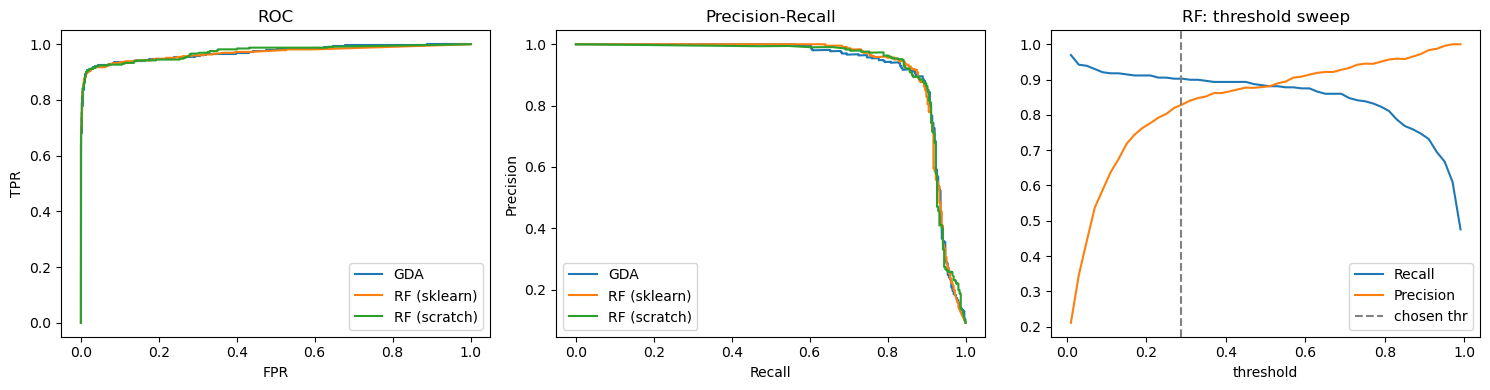

In [9]:
sup = run_supervised(Xtr, ytr, Xte, yte, scratch_trees=SCRATCH_TREES)

c:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=7.
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=7.
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=7.
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Window

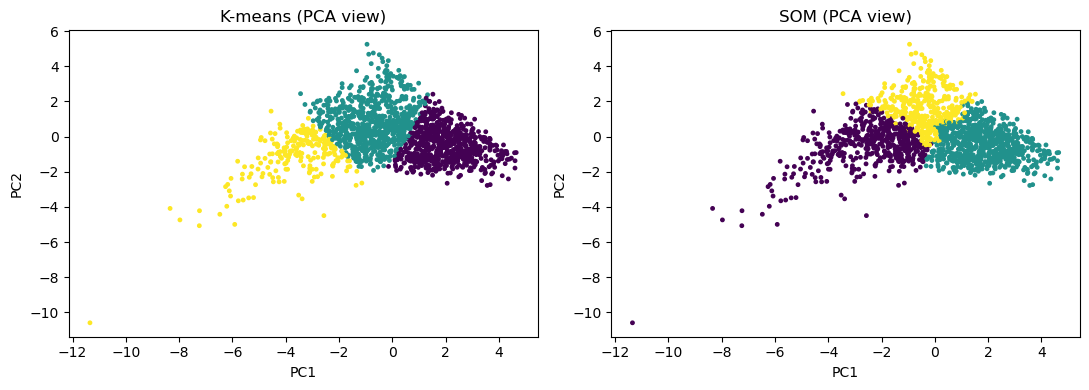

In [10]:
unsup = run_unsupervised(X[y == 1], som_epochs=SOM_EPOCHS)

In [11]:
results = {"supervised": sup, "unsupervised": unsup}
with open("results/results.json", "w") as f:
    json.dump(results, f, indent=2)

rows = {"GDA (baseline)": sup["gda_test"], "RF sklearn, thr 0.5": sup["rf_test_thr0.5"],
        f"RF sklearn, thr {sup['rf_threshold']:.3f}": sup["rf_test_tuned_thr"], "RF from scratch": sup["rf_scratch_test"]}
print("Test-set results")
display((pd.DataFrame(rows).T * 100).round(2).assign(auc=lambda d: d["auc"] / 100).round(3))
print("Best RF hyper-parameters:", sup["rf_best_params"])
print("K-means:", unsup["kmeans"])
print("SOM:", unsup["som"])
print("PCA explained variance:", unsup["pca_explained_variance"])

Test-set results


,accuracy,recall,precision,f1,auc
GDA (baseline),97.91,89.63,87.76,88.69,0.971
"RF sklearn, thr 0.5",97.82,88.41,87.88,88.15,0.969
"RF sklearn, thr 0.286",97.40,90.24,82.91,86.42,0.969
RF from scratch,97.82,89.94,86.76,88.32,0.973


Best RF hyper-parameters: {'n_estimators': 200, 'min_samples_split': 10, 'max_features': 'sqrt', 'max_depth': 60}
K-means: {'k': 3, 'silhouette': 0.3347762711269899, 'sizes': [679, 739, 221]}
SOM: {'non_empty_cells': 25, 'silhouette_all_cells': 0.09490956728555278, 'silhouette_k_groups': 0.3137306550970776, 'sizes': [508, 753, 378]}
PCA explained variance: [0.5881416014270391, 0.23166874068020157]


## 9. Conclusions
- All classifiers reach ~97-98% accuracy and ~88-90% recall from 8 summary features.
- Random Forest does not clearly beat the GDA baseline; differences are only a few pulsars out of the test set.
- Lowering the RF threshold trades precision for recall.
- Pulsar clusters are only moderately separated (silhouette ~0.31-0.34); the features lack period/frequency information.